# Tornado Prediction using Machine Learning

Predicting tornado occurrence in Texas using ERA5 weather data and NOAA storm records.

**Data Sources:**
- ERA5 Reanalysis (Copernicus Climate Data Store)
- NOAA Storm Events Database
- Pre-processed local features

**Models:**
- Random Forest
- Convolutional Neural Network (CNN)
- Long Short-Term Memory (LSTM)

In [ ]:
# install dependencies
!pip install -q cdsapi xarray netcdf4 cfgrib eccodes tensorflow

Imports and Data Loading

In [ ]:
# imports
from pathlib import Path
import sys, re, json, gzip, requests, warnings
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                            f1_score, roc_auc_score, confusion_matrix, 
                            roc_curve, classification_report)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

np.random.seed(42)
tf.random.set_seed(42)
warnings.filterwarnings('ignore')

# environment check
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    DATA_ROOT = Path('/content')
else:
    DATA_ROOT = Path('.') if Path('./data/processed').exists() else Path(__file__).parent if '__file__' in dir() else Path('.')

# directories
PROCESSED_DIR = DATA_ROOT / 'data' / 'processed'
ERA5_DIR = DATA_ROOT / 'data' / 'era5_cache'
OUTPUT_DIR = DATA_ROOT / 'outputs'

for d in [PROCESSED_DIR, ERA5_DIR, OUTPUT_DIR]:
    d.mkdir(exist_ok=True, parents=True)

# texas region
TEXAS_BBOX = [36.5, -106.6, 25.8, -93.5]

# settings
CDS_KEY = 'b6a18ea7-c2f3-49d5-a828-94b1a891c054'
GRID_SIZE = 2.5
N_DAYS = 5

# cds api credentials
cdsrc = Path('/root/.cdsapirc') if IN_COLAB else Path.home() / '.cdsapirc'
if not cdsrc.exists():
    cdsrc.write_text(f'url: https://cds.climate.copernicus.eu/api\nkey: {CDS_KEY}\n')

print(f"Data Directory: {DATA_ROOT.resolve()}")

Environment: Local
Data Directory: D:\Sorbonne M1\DALAS\Project\project


c:\Users\abdul\miniconda3\envs\bima\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


## Loading Dataset
We fetch data from ERA5 API,
We also downloaded data from them to local system.

In [2]:
# download tornado records from NOAA Storm Events Database
NOAA_URL = 'https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/'

def get_noaa_tornadoes(years):
    cache = ERA5_DIR
    all_data = []
    
    for yr in years:
        print(f"Fetching NOAA {yr}...", end=' ')
        try:
            resp = requests.get(NOAA_URL, timeout=30)
            files = re.findall(rf'StormEvents_details-ftp_v1\.0_d{yr}_c\d+\.csv\.gz', resp.text)
            if not files:
                print("not found")
                continue
            
            fname = files[-1]
            fpath = cache / fname
            
            if not fpath.exists():
                data = requests.get(NOAA_URL + fname, timeout=120).content
                fpath.write_bytes(data)
            
            with gzip.open(fpath, 'rt', encoding='latin-1') as f:
                df = pd.read_csv(f, low_memory=False)
            
            tx_tornado = df[(df['EVENT_TYPE'] == 'Tornado') & (df['STATE'] == 'TEXAS')].copy()
            print(f"{len(tx_tornado)} tornadoes")
            all_data.append(tx_tornado)
        except Exception as e:
            print(f"error: {e}")
    
    if not all_data:
        return pd.DataFrame()
    
    combined = pd.concat(all_data, ignore_index=True)
    combined = combined.dropna(subset=['BEGIN_LAT', 'BEGIN_LON'])
    combined = combined[(combined['BEGIN_LAT'] != 0) & (combined['BEGIN_LON'] != 0)]
    combined['event_date'] = pd.to_datetime(combined['BEGIN_DATE_TIME'], errors='coerce')
    combined = combined.dropna(subset=['event_date'])
    
    print(f"Total: {len(combined)} Texas tornadoes")
    return combined

In [3]:
# era5 weather data download
ERA5_VARS = [
    '10m_u_component_of_wind', '10m_v_component_of_wind',
    '2m_temperature', 'total_precipitation',
    'total_cloud_cover', 'surface_pressure',
]

VAR_NAMES = {
    'u10': 'wind_u', 'v10': 'wind_v', 't2m': 'temp',
    'tp': 'precip', 'tcc': 'cloud', 'sp': 'pressure'
}

def download_era5(year, month):
    import cdsapi
    
    out = ERA5_DIR / f'era5_{year}_{month:02d}.grib'
    if out.exists():
        print(f"[cached] {out.name}")
        return out
    
    print(f"downloading era5 {year}-{month:02d}...")
    c = cdsapi.Client()
    c.retrieve('reanalysis-era5-single-levels', {
        'product_type': ['reanalysis'],
        'variable': ERA5_VARS,
        'year': [str(year)],
        'month': [f'{month:02d}'],
        'day': [f'{d:02d}' for d in range(1, 32)],
        'time': ['00:00', '12:00'],  # just 2 times per day to speed up
        'area': TEXAS_BBOX,
        'data_format': 'grib',
    }, str(out))
    
    print(f"done: {out.stat().st_size / 1024 / 1024:.1f} MB")
    return out


def load_era5(fpath):
    import xarray as xr
    import cfgrib
    
    print(f"loading {fpath.name}...")
    datasets = cfgrib.open_datasets(str(fpath))
    
    # merge all the datasets together
    merged = {}
    coords = None
    
    for ds in datasets:
        # figure out time coord
        if 'valid_time' in ds.coords:
            vt = ds.coords['valid_time']
            times = vt.values.flatten() if len(vt.dims) > 1 else vt.values
            times = np.unique(times[~np.isnat(times.flatten())]) if hasattr(times.flatten()[0], 'year') else times
        else:
            times = ds.coords['time'].values
        
        if coords is None:
            lat = 'latitude' if 'latitude' in ds.coords else 'lat'
            lon = 'longitude' if 'longitude' in ds.coords else 'lon'
            coords = {'time': np.sort(times), lat: ds.coords[lat].values, lon: ds.coords[lon].values}
        
        for v in ds.data_vars:
            arr = ds[v].values
            # avg over step dim if exists
            if 'step' in ds[v].dims:
                arr = np.nanmean(arr, axis=ds[v].dims.index('step'))
            while len(arr.shape) > 3:
                arr = np.nanmean(arr, axis=-3)
            merged[v] = arr
    
    # build xarray dataset
    lat = 'latitude' if 'latitude' in coords else 'lat'
    lon = 'longitude' if 'longitude' in coords else 'lon'
    
    dvars = {}
    for v, arr in merged.items():
        exp_shape = (len(coords['time']), len(coords[lat]), len(coords[lon]))
        if arr.shape == exp_shape:
            dvars[v] = (['time', lat, lon], arr)
        elif len(arr.shape) == 2:
            dvars[v] = ([lat, lon], arr)
    
    result = xr.Dataset(dvars, coords=coords)
    print(f"  vars: {list(result.data_vars)}")
    return result

Feature Extraction

In [4]:
# extract features from era5 grid around each event location
def extract_quadrant_features(era5, events, label_val):
    lat_key = 'latitude' if 'latitude' in era5.coords else 'lat'
    lon_key = 'longitude' if 'longitude' in era5.coords else 'lon'
    
    time_key = 'time' if 'time' in era5.dims else 'valid_time'
    times = pd.to_datetime(era5[time_key].values)
    t_min, t_max = times.min(), times.max()
    
    lats = era5[lat_key].values
    descending = lats[0] > lats[-1]
    
    rows = []
    for i, (_, ev) in enumerate(events.iterrows()):
        if i % 100 == 0:
            print(f"  processing {i}/{len(events)}")
        
        try:
            dt = ev['event_date']
            if dt < t_min + timedelta(days=N_DAYS-1) or dt > t_max:
                continue
            
            feat = {'label': label_val, 'year': dt.year}
            
            for day in range(N_DAYS):
                target = dt - timedelta(days=day)
                
                # get 5x5 degree box around location
                lat_lo, lat_hi = ev['BEGIN_LAT'] - GRID_SIZE, ev['BEGIN_LAT'] + GRID_SIZE
                lon_lo, lon_hi = ev['BEGIN_LON'] - GRID_SIZE, ev['BEGIN_LON'] + GRID_SIZE
                
                lat_sl = slice(lat_hi, lat_lo) if descending else slice(lat_lo, lat_hi)
                
                try:
                    chunk = era5.sel({time_key: target.strftime('%Y-%m-%d')}, method='nearest')
                    chunk = chunk.sel({lat_key: lat_sl, lon_key: slice(lon_lo, lon_hi)})
                    
                    for var in chunk.data_vars:
                        arr = chunk[var].values
                        while len(arr.shape) > 2:
                            arr = np.nanmean(arr, axis=0)
                        
                        if arr.size < 4:
                            continue
                        
                        # split into 4 quadrants
                        r, c = arr.shape
                        mr, mc = max(1, r//2), max(1, c//2)
                        quads = [arr[:mr,:mc], arr[:mr,mc:], arr[mr:,:mc], arr[mr:,mc:]]
                        
                        vname = VAR_NAMES.get(var, var)
                        for qi, q in enumerate(quads):
                            if q.size > 0:
                                feat[f'{vname}-Q{qi}-mean_day{day}'] = float(np.nanmean(q))
                                feat[f'{vname}-Q{qi}-std_day{day}'] = float(np.nanstd(q))
                except:
                    pass
            
            if len(feat) > 10:  # need at least some features
                rows.append(feat)
        except:
            pass
    
    return pd.DataFrame(rows) if rows else None


def make_negative_samples(era5, tornado_df, n):
    lat_key = 'latitude' if 'latitude' in era5.coords else 'lat'
    lon_key = 'longitude' if 'longitude' in era5.coords else 'lon'
    time_key = 'time' if 'time' in era5.dims else 'valid_time'
    
    lats = era5[lat_key].values
    lons = era5[lon_key].values
    times = pd.to_datetime(era5[time_key].values)
    
    # locations to avoid (where tornadoes happened)
    bad_locs = set((round(e['BEGIN_LAT']), round(e['BEGIN_LON'])) for _, e in tornado_df.iterrows())
    
    samples = []
    tries = 0
    while len(samples) < n and tries < n * 50:
        tries += 1
        lat = np.random.uniform(lats.min() + GRID_SIZE, lats.max() - GRID_SIZE)
        lon = np.random.uniform(lons.min() + GRID_SIZE, lons.max() - GRID_SIZE)
        t = np.random.choice(times[N_DAYS:]) if len(times) > N_DAYS else times[0]
        
        if (round(lat), round(lon)) not in bad_locs:
            samples.append({'BEGIN_LAT': lat, 'BEGIN_LON': lon, 'event_date': pd.Timestamp(t)})
    
    print(f"  generated {len(samples)} negative samples")
    return extract_quadrant_features(era5, pd.DataFrame(samples), 0)

In [5]:
# load pre-processed local data
def load_local():
    feat_file = PROCESSED_DIR / 'features_4Q_days0-4.csv'
    label_file = PROCESSED_DIR / 'labels_4Q_days0-4.csv'
    
    if feat_file.exists() and label_file.exists():
        X = pd.read_csv(feat_file)
        y = pd.read_csv(label_file)['label']
        print(f"Loaded local data: {X.shape[0]} samples, {X.shape[1]} features")
        return X, y
    
    print(f"Local data not found at {PROCESSED_DIR}")
    return None, None

## load and combine data

In [6]:
# load and combine datasets
print("Loading Local Preprocessed Data")
X_local, y_local = load_local()

api_features = None
print("Fetching Fresh API Data (ERA5 + NOAA)")

try:
    tornado_events = get_noaa_tornadoes(range(2019, 2026))
    
    if len(tornado_events) > 0:
        print(f"\nTornado events by year:")
        print(tornado_events['YEAR'].value_counts().sort_index())
        
        # get required months
        months = set()
        for dt in tornado_events['event_date']:
            for d in range(N_DAYS):
                t = dt - timedelta(days=d)
                months.add((t.year, t.month))
        months = sorted(months)
        
        print(f"\nTotal months needed: {len(months)}")
        
        # download tornado season months (march-june) for better coverage
        tornado_months = [(y, m) for y, m in months if m in [3, 4, 5, 6]][:6]
        print(f"Downloading {len(tornado_months)} tornado season months...")
        
        all_tornado_feats = []
        all_neg_feats = []
        
        for year, month in tornado_months:
            try:
                f = download_era5(year, month)
                ds = load_era5(f)
                
                print(f"\nExtracting features for {year}-{month:02d}...")
                pos = extract_quadrant_features(ds, tornado_events, 1)
                if pos is not None and len(pos) > 0:
                    print(f"  Tornado samples: {len(pos)}")
                    all_tornado_feats.append(pos)
                    
                    neg = make_negative_samples(ds, tornado_events, len(pos))
                    if neg is not None:
                        all_neg_feats.append(neg)
                
                ds.close()
            except Exception as e:
                print(f"  Error: {e}")
        
        if all_tornado_feats:
            pos_df = pd.concat(all_tornado_feats, ignore_index=True)
            neg_df = pd.concat(all_neg_feats, ignore_index=True) if all_neg_feats else pd.DataFrame()
            
            if len(neg_df) > 0:
                cols = list(set(pos_df.columns) & set(neg_df.columns))
                api_features = pd.concat([pos_df[cols], neg_df[cols]], ignore_index=True)
                print(f"\nAPI data extracted: {len(api_features)} samples")
except Exception as e:
    print(f"API data extraction failed: {e}")

# combine datasets
print("Combining Datasets")

if X_local is not None and api_features is not None:
    local_df = X_local.copy()
    local_df['label'] = y_local.values
    api_df = api_features.copy()
    
    local_feats = set(c for c in local_df.columns if c not in ['label', 'year'])
    api_feats = set(c for c in api_df.columns if c not in ['label', 'year'])
    
    print(f"Local features: {len(local_feats)}")
    print(f"API features: {len(api_feats)}")
    
    all_cols = list(local_feats | api_feats)
    for c in all_cols:
        if c not in local_df.columns:
            local_df[c] = 0
        if c not in api_df.columns:
            api_df[c] = 0
    
    combined = pd.concat([local_df, api_df], ignore_index=True)
    y = combined['label'].astype(int)
    X_df = combined.drop(columns=['label'])
    if 'year' in X_df.columns:
        X_df = X_df.drop(columns=['year'])
    
    print(f"Combined dataset: {X_df.shape}")
    
elif X_local is not None:
    X_df = X_local.copy()
    y = y_local.copy()
    print(f"Using local data only: {X_df.shape}")
    
elif api_features is not None:
    feat_cols = [c for c in api_features.columns if c not in ['label', 'year']]
    X_df = api_features[feat_cols]
    y = api_features['label'].astype(int)
    print(f"Using API data only: {X_df.shape}")
else:
    raise ValueError("No data available!")

print(f"\nFinal Dataset Shape: {X_df.shape}")
print(f"Class Distribution: {dict(zip(['Non-Tornado', 'Tornado'], np.bincount(y.astype(int))))}")

Loading Local Preprocessed Data
Loaded local data: 5283 samples, 400 features

Fetching Fresh API Data (ERA5 + NOAA)
Fetching NOAA 2019... 184 tornadoes
Fetching NOAA 2020... 92 tornadoes
Fetching NOAA 2021... 103 tornadoes
Fetching NOAA 2022... 142 tornadoes
Fetching NOAA 2023... 82 tornadoes
Fetching NOAA 2024... 149 tornadoes
Fetching NOAA 2025... 132 tornadoes
Total: 884 Texas tornadoes

Tornado events by year:
YEAR
2019    184
2020     92
2021    103
2022    142
2023     82
2024    149
2025    132
Name: count, dtype: int64

Total months needed: 65
downloading era5 2019-03...


2026-01-09 23:32:51,603 INFO [2025-12-11T00:00:00] Please note that a dedicated catalogue entry for this dataset, post-processed and stored in Analysis Ready Cloud Optimized (ARCO) format (Zarr), is available for optimised time-series retrievals (i.e. for retrieving data from selected variables for a single point over an extended period of time in an efficient way). You can discover it [here](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=overview)
2026-01-09 23:32:51,604 INFO Request ID is f692846b-0d94-477f-9fef-3466bee4a300
2026-01-09 23:32:51,668 INFO status has been updated to accepted
2026-01-09 23:33:00,066 INFO status has been updated to successful


68694318b12106eeb2847b82625877d0.grib:   0%|          | 0.00/1.66M [00:00<?, ?B/s]

done: 1.7 MB
loading era5_2019_03.grib...
  vars: ['sp', 'tcc', 'u10', 'v10', 't2m', 'tp']

Extracting features for 2019-03...
  processing 0/884
  processing 100/884
  processing 200/884
  processing 300/884
  processing 400/884
  processing 500/884
  processing 600/884
  processing 700/884
  processing 800/884
  Tornado samples: 12
  generated 12 negative samples
  processing 0/12
downloading era5 2019-04...


2026-01-09 23:33:02,960 INFO [2025-12-11T00:00:00] Please note that a dedicated catalogue entry for this dataset, post-processed and stored in Analysis Ready Cloud Optimized (ARCO) format (Zarr), is available for optimised time-series retrievals (i.e. for retrieving data from selected variables for a single point over an extended period of time in an efficient way). You can discover it [here](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=overview)
2026-01-09 23:33:02,961 INFO Request ID is eae9d3a2-f738-4e9e-ac1e-e94cfccfbba0
2026-01-09 23:33:03,022 INFO status has been updated to accepted
2026-01-09 23:33:11,360 INFO status has been updated to running
2026-01-09 23:33:16,489 INFO status has been updated to successful


...

98a740a6ce5f2874c513e9597357c783.grib:   0%|          | 0.00/1.66M [00:00<?, ?B/s]

done: 1.7 MB
loading era5_2020_03.grib...
  vars: ['sp', 'tcc', 'u10', 'v10', 't2m', 'tp']

Extracting features for 2020-03...
  processing 0/884
  processing 100/884
  processing 200/884
  processing 300/884
  processing 400/884
  processing 500/884
  processing 600/884
  processing 700/884
  processing 800/884
  Tornado samples: 18
  generated 18 negative samples
  processing 0/18
downloading era5 2020-04...


2026-01-09 23:34:17,198 INFO [2025-12-11T00:00:00] Please note that a dedicated catalogue entry for this dataset, post-processed and stored in Analysis Ready Cloud Optimized (ARCO) format (Zarr), is available for optimised time-series retrievals (i.e. for retrieving data from selected variables for a single point over an extended period of time in an efficient way). You can discover it [here](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=overview)
2026-01-09 23:34:17,199 INFO Request ID is 29abeef2-7157-48c5-ad33-f3984dd3f2ca
2026-01-09 23:34:17,250 INFO status has been updated to accepted
2026-01-09 23:34:30,757 INFO status has been updated to successful


b1e26880e6f2cb23547069f4c89b091a.grib:   0%|          | 0.00/1.60M [00:00<?, ?B/s]

done: 1.6 MB
loading era5_2020_04.grib...
  vars: ['sp', 'tcc', 'u10', 'v10', 't2m', 'tp']

Extracting features for 2020-04...
  processing 0/884
  processing 100/884
  processing 200/884
  processing 300/884
  processing 400/884
  processing 500/884
  processing 600/884
  processing 700/884
  processing 800/884
  Tornado samples: 17
  generated 17 negative samples
  processing 0/17

API data extracted: 350 samples

Combining Datasets
Local features: 400
API features: 240
Combined dataset: (5633, 640)

Final Dataset Shape: (5633, 640)
Class Distribution: {'Non-Tornado': np.int64(2940), 'Tornado': np.int64(2693)}


## Data Visualization

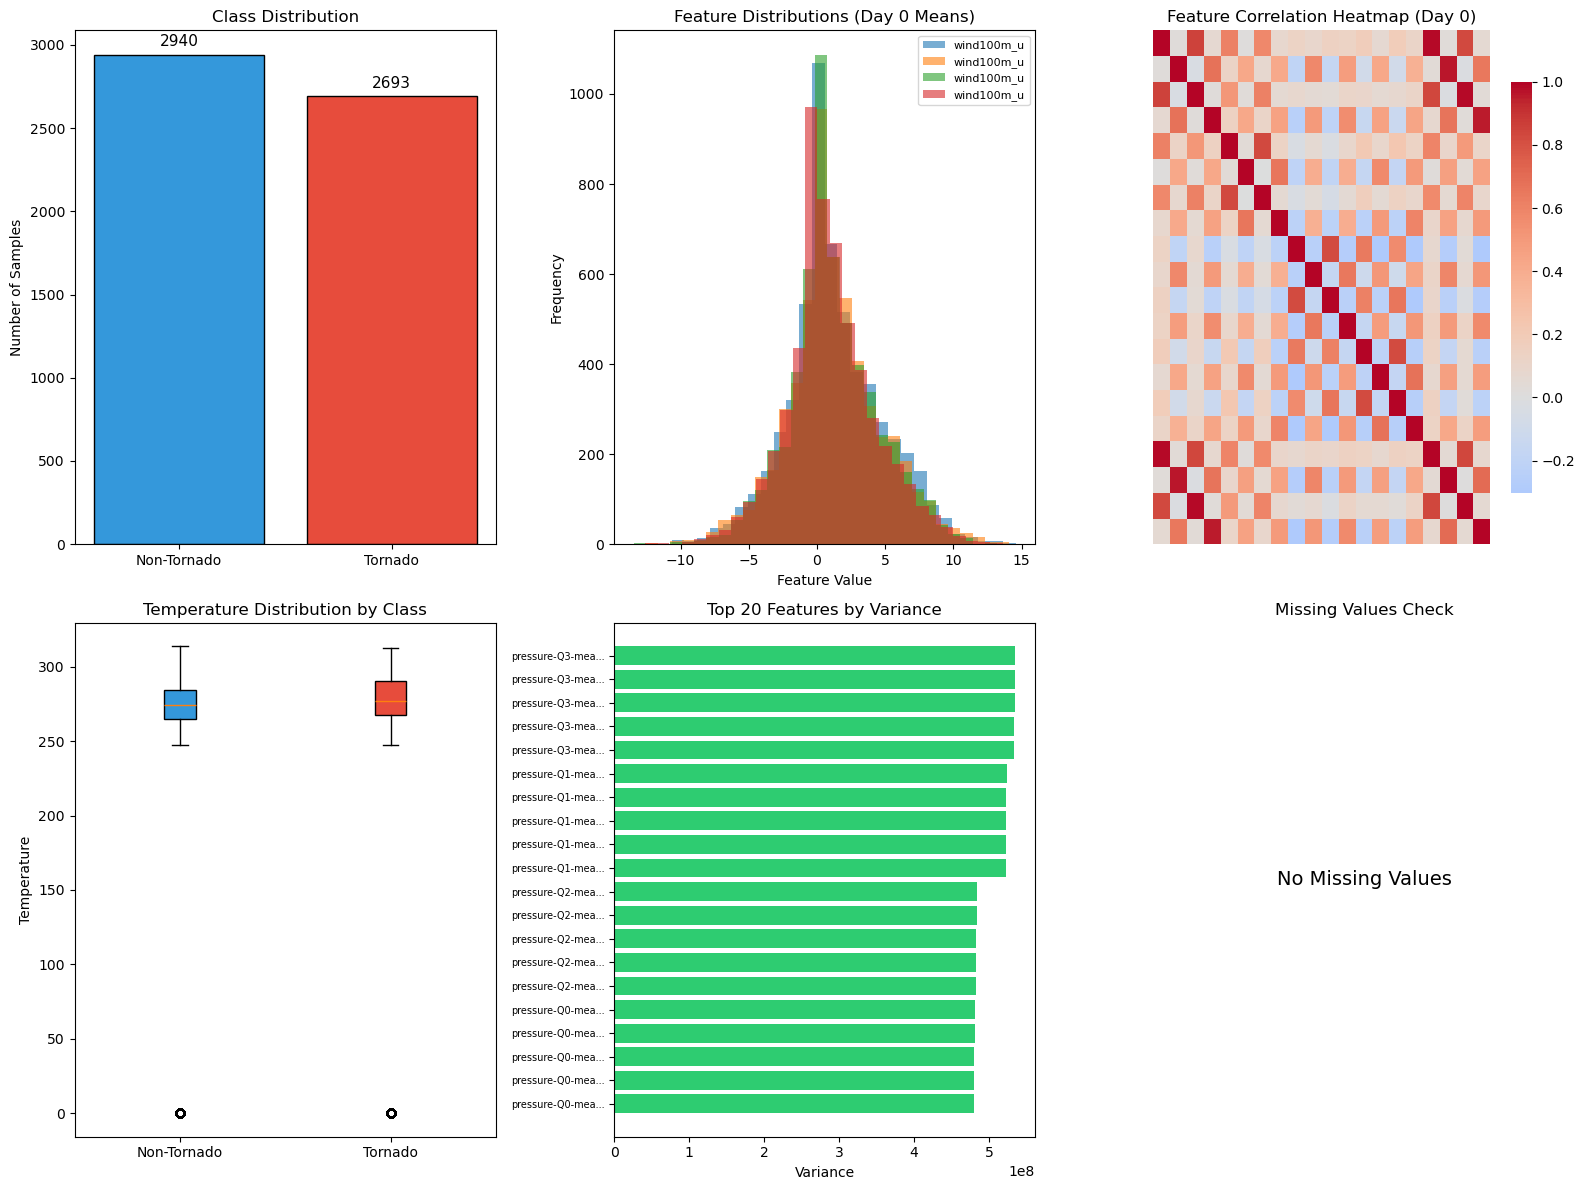


Dataset Statistics:
  Total samples: 5633
  Total features: 640
  Class balance: 0.92 (tornado/non-tornado ratio)


In [7]:
# data visualization
fig = plt.figure(figsize=(16, 12))

# 1. class distribution
ax1 = fig.add_subplot(2, 3, 1)
classes = ['Non-Tornado', 'Tornado']
counts = np.bincount(y.astype(int))
colors = ['#3498db', '#e74c3c']
bars = ax1.bar(classes, counts, color=colors, edgecolor='black')
ax1.set_ylabel('Number of Samples')
ax1.set_title('Class Distribution')
for bar, count in zip(bars, counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             str(count), ha='center', fontsize=11)

# 2. feature distribution histogram (sample features)
ax2 = fig.add_subplot(2, 3, 2)
sample_cols = [c for c in X_df.columns if 'mean_day0' in c][:4]
for i, col in enumerate(sample_cols):
    ax2.hist(X_df[col].dropna(), bins=30, alpha=0.6, label=col.split('-')[0])
ax2.set_xlabel('Feature Value')
ax2.set_ylabel('Frequency')
ax2.set_title('Feature Distributions (Day 0 Means)')
ax2.legend(fontsize=8)

# 3. correlation heatmap (subset of features)
ax3 = fig.add_subplot(2, 3, 3)
day0_cols = [c for c in X_df.columns if 'day0' in c][:20]
if len(day0_cols) > 5:
    corr_matrix = X_df[day0_cols].corr()
    sns.heatmap(corr_matrix, ax=ax3, cmap='coolwarm', center=0, 
                xticklabels=False, yticklabels=False, cbar_kws={'shrink': 0.8})
ax3.set_title('Feature Correlation Heatmap (Day 0)')

# 4. box plot by class
ax4 = fig.add_subplot(2, 3, 4)
temp_cols = [c for c in X_df.columns if 'temp' in c.lower() and 'mean' in c][:1]
if temp_cols:
    data_tornado = X_df.loc[y == 1, temp_cols[0]].dropna()
    data_other = X_df.loc[y == 0, temp_cols[0]].dropna()
    bp = ax4.boxplot([data_other, data_tornado], labels=['Non-Tornado', 'Tornado'], patch_artist=True)
    bp['boxes'][0].set_facecolor('#3498db')
    bp['boxes'][1].set_facecolor('#e74c3c')
    ax4.set_ylabel('Temperature')
    ax4.set_title('Temperature Distribution by Class')

# 5. feature variance
ax5 = fig.add_subplot(2, 3, 5)
variances = X_df.var().sort_values(ascending=False)[:20]
ax5.barh(range(len(variances)), variances.values, color='#2ecc71')
ax5.set_yticks(range(len(variances)))
ax5.set_yticklabels([v[:15] + '...' if len(v) > 15 else v for v in variances.index], fontsize=7)
ax5.set_xlabel('Variance')
ax5.set_title('Top 20 Features by Variance')
ax5.invert_yaxis()

# 6. missing values
ax6 = fig.add_subplot(2, 3, 6)
missing = X_df.isnull().sum()
missing_pct = (missing / len(X_df) * 100).sort_values(ascending=False)[:10]
if missing_pct.sum() > 0:
    ax6.bar(range(len(missing_pct)), missing_pct.values, color='#9b59b6')
    ax6.set_xticks(range(len(missing_pct)))
    ax6.set_xticklabels([v[:10] for v in missing_pct.index], rotation=45, ha='right', fontsize=8)
    ax6.set_ylabel('Missing (%)')
    ax6.set_title('Missing Values by Feature')
else:
    ax6.text(0.5, 0.5, 'No Missing Values', ha='center', va='center', fontsize=14)
    ax6.set_title('Missing Values Check')
    ax6.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'data_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nDataset Statistics:")
print(f"  Total samples: {len(X_df)}")
print(f"  Total features: {X_df.shape[1]}")
print(f"  Class balance: {counts[1]/counts[0]:.2f} (tornado/non-tornado ratio)")

## Defining ML Models
1. CNN
2. LSTM
3. Random Forest

In [8]:
# model architectures

def build_random_forest():
    return RandomForestClassifier(
        n_estimators=200, 
        max_depth=15, 
        class_weight='balanced', 
        random_state=42, 
        n_jobs=-1
    )

def build_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.Conv1D(64, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(
        optimizer='adam', 
        loss='binary_crossentropy', 
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

def build_lstm(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.LSTM(64, return_sequences=True),
        layers.LSTM(32),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001), 
        loss='binary_crossentropy', 
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

In [9]:
# data preparation and training functions

def prepare_data(X, y):
    X_arr = X.values.astype(np.float32)
    y_arr = np.array(y).astype(np.int32)
    X_arr = np.nan_to_num(X_arr, nan=0.0)
    
    # split: 70% train, 10% val, 20% test
    X_temp, X_test, y_temp, y_test = train_test_split(
        X_arr, y_arr, test_size=0.2, stratify=y_arr, random_state=42
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=42
    )
    
    # standardize
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)
    
    # reshape for sequential models
    n_features = X_train.shape[1]
    if n_features % N_DAYS != 0:
        pad = N_DAYS - (n_features % N_DAYS)
        X_train = np.pad(X_train, ((0, 0), (0, pad)))
        X_val = np.pad(X_val, ((0, 0), (0, pad)))
        X_test = np.pad(X_test, ((0, 0), (0, pad)))
    
    features_per_day = X_train.shape[1] // N_DAYS
    X_train_seq = X_train.reshape(-1, N_DAYS, features_per_day)
    X_val_seq = X_val.reshape(-1, N_DAYS, features_per_day)
    X_test_seq = X_test.reshape(-1, N_DAYS, features_per_day)
    
    print(f"Training set: {len(y_train)} samples")
    print(f"Validation set: {len(y_val)} samples")
    print(f"Test set: {len(y_test)} samples")
    
    return X_train, X_val, X_test, X_train_seq, X_val_seq, X_test_seq, y_train, y_val, y_test, scaler


def train_all_models(X_train, X_val, X_test, X_train_seq, X_val_seq, X_test_seq, y_train, y_val, y_test):
    results = {}
    predictions = {'y_true': y_test}
    trained_models = {}
    histories = {}
    
    early_stopping = callbacks.EarlyStopping(
        monitor='val_auc', patience=15, restore_best_weights=True, mode='max'
    )
    
    # Random Forest
    print("\nTraining Random Forest...")
    rf_model = build_random_forest()
    rf_model.fit(X_train, y_train)
    rf_pred = rf_model.predict(X_test)
    rf_prob = rf_model.predict_proba(X_test)[:, 1]
    
    results['Random Forest'] = {
        'Accuracy': accuracy_score(y_test, rf_pred),
        'Precision': precision_score(y_test, rf_pred, zero_division=0),
        'Recall': recall_score(y_test, rf_pred, zero_division=0),
        'F1 Score': f1_score(y_test, rf_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, rf_prob),
    }
    predictions['Random Forest'] = rf_prob
    trained_models['Random Forest'] = rf_model
    print(f"  Random Forest - Accuracy: {results['Random Forest']['Accuracy']:.4f}, F1: {results['Random Forest']['F1 Score']:.4f}")
    
    # CNN
    print("\nTraining Convolutional Neural Network...")
    cnn_model = build_cnn(X_train_seq.shape[1:])
    cnn_history = cnn_model.fit(
        X_train_seq, y_train,
        validation_data=(X_val_seq, y_val),
        epochs=100, batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )
    cnn_prob = cnn_model.predict(X_test_seq, verbose=0).flatten()
    cnn_pred = (cnn_prob > 0.5).astype(int)
    
    results['CNN'] = {
        'Accuracy': accuracy_score(y_test, cnn_pred),
        'Precision': precision_score(y_test, cnn_pred, zero_division=0),
        'Recall': recall_score(y_test, cnn_pred, zero_division=0),
        'F1 Score': f1_score(y_test, cnn_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, cnn_prob),
    }
    predictions['CNN'] = cnn_prob
    trained_models['CNN'] = cnn_model
    histories['CNN'] = cnn_history.history
    print(f"  CNN - Accuracy: {results['CNN']['Accuracy']:.4f}, F1: {results['CNN']['F1 Score']:.4f}")
    
    # LSTM
    print("\nTraining Long Short-Term Memory Network...")
    lstm_model = build_lstm(X_train_seq.shape[1:])
    lstm_history = lstm_model.fit(
        X_train_seq, y_train,
        validation_data=(X_val_seq, y_val),
        epochs=100, batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )
    lstm_prob = lstm_model.predict(X_test_seq, verbose=0).flatten()
    lstm_pred = (lstm_prob > 0.5).astype(int)
    
    results['LSTM'] = {
        'Accuracy': accuracy_score(y_test, lstm_pred),
        'Precision': precision_score(y_test, lstm_pred, zero_division=0),
        'Recall': recall_score(y_test, lstm_pred, zero_division=0),
        'F1 Score': f1_score(y_test, lstm_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, lstm_prob),
    }
    predictions['LSTM'] = lstm_prob
    trained_models['LSTM'] = lstm_model
    histories['LSTM'] = lstm_history.history
    print(f"  LSTM - Accuracy: {results['LSTM']['Accuracy']:.4f}, F1: {results['LSTM']['F1 Score']:.4f}")
    
    return results, predictions, trained_models, histories

## Model Training

In [10]:
# prepare data and train models
print("Data Preparation (70% Train / 10% Validation / 20% Test)")

X_train, X_val, X_test, X_train_seq, X_val_seq, X_test_seq, y_train, y_val, y_test, scaler = prepare_data(X_df, y)

print("Model Training")

results, predictions, trained_models, histories = train_all_models(
    X_train, X_val, X_test, X_train_seq, X_val_seq, X_test_seq, y_train, y_val, y_test
)

print("Results Summary")
results_df = pd.DataFrame(results).T
print(results_df.round(4).to_string())

Data Preparation (70% Train / 10% Validation / 20% Test)
Training set: 3942 samples
Validation set: 564 samples
Test set: 1127 samples

Model Training

Training Random Forest...
  Random Forest - Accuracy: 0.7773, F1: 0.7502

Training Convolutional Neural Network...
  CNN - Accuracy: 0.7303, F1: 0.7116

Training Long Short-Term Memory Network...
  LSTM - Accuracy: 0.7258, F1: 0.7224

Results Summary
               Accuracy  Precision  Recall  F1 Score  ROC AUC
Random Forest    0.7773     0.8090  0.6994    0.7502   0.8619
CNN              0.7303     0.7282  0.6957    0.7116   0.7865
LSTM             0.7258     0.7003  0.7458    0.7224   0.8054


## Individual Model Evaluation

Confusion matrices, learning curves, and detailed metrics for each model.

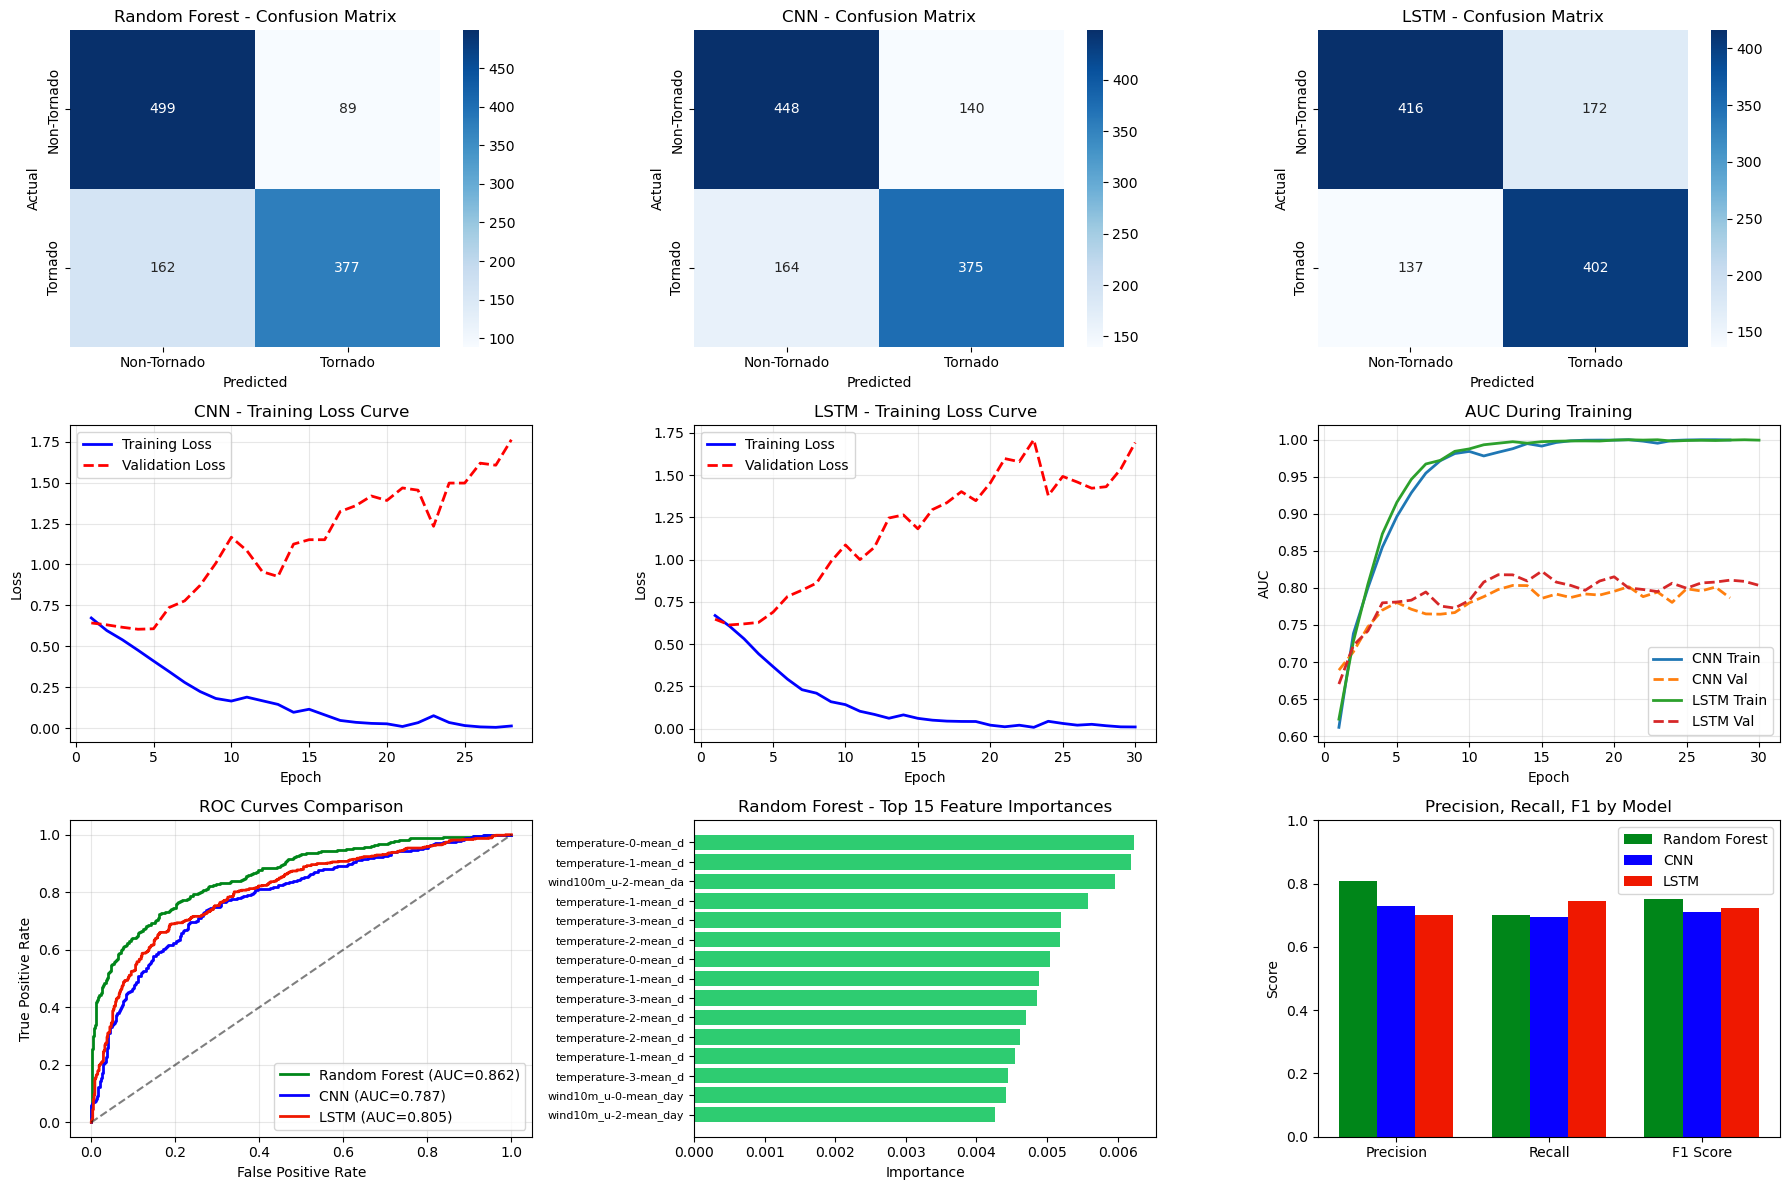


Detailed Classification Reports

Random Forest:
----------------------------------------
              precision    recall  f1-score   support

 Non-Tornado       0.75      0.85      0.80       588
     Tornado       0.81      0.70      0.75       539

    accuracy                           0.78      1127
   macro avg       0.78      0.77      0.77      1127
weighted avg       0.78      0.78      0.78      1127


CNN:
----------------------------------------
              precision    recall  f1-score   support

 Non-Tornado       0.73      0.76      0.75       588
     Tornado       0.73      0.70      0.71       539

    accuracy                           0.73      1127
   macro avg       0.73      0.73      0.73      1127
weighted avg       0.73      0.73      0.73      1127


LSTM:
----------------------------------------
              precision    recall  f1-score   support

 Non-Tornado       0.75      0.71      0.73       588
     Tornado       0.70      0.75      0.72       53

In [11]:
# individual model evaluation - confusion matrices and learning curves
fig = plt.figure(figsize=(18, 12))

model_names = ['Random Forest', 'CNN', 'LSTM']
colors = {'Random Forest': "#008619", 'CNN': "#0800ff", 'LSTM': "#ef1800"}

# row 1: confusion matrices
for i, name in enumerate(model_names):
    ax = fig.add_subplot(3, 3, i + 1)
    
    prob = predictions[name]
    pred = (prob > 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-Tornado', 'Tornado'],
                yticklabels=['Non-Tornado', 'Tornado'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'{name} - Confusion Matrix')

# row 2: learning curves (for neural networks)
for i, name in enumerate(['CNN', 'LSTM']):
    ax = fig.add_subplot(3, 3, 4 + i)
    
    if name in histories:
        history = histories[name]
        epochs = range(1, len(history['loss']) + 1)
        
        ax.plot(epochs, history['loss'], 'b-', label='Training Loss', linewidth=2)
        ax.plot(epochs, history['val_loss'], 'r--', label='Validation Loss', linewidth=2)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.set_title(f'{name} - Training Loss Curve')
        ax.legend()
        ax.grid(True, alpha=0.3)

# row 2, col 3: AUC curves
ax = fig.add_subplot(3, 3, 6)
for name in ['CNN', 'LSTM']:
    if name in histories:
        history = histories[name]
        epochs = range(1, len(history['auc']) + 1)
        ax.plot(epochs, history['auc'], label=f'{name} Train', linewidth=2)
        ax.plot(epochs, history['val_auc'], '--', label=f'{name} Val', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('AUC')
ax.set_title('AUC During Training')
ax.legend()
ax.grid(True, alpha=0.3)

# row 3: ROC curves
ax = fig.add_subplot(3, 3, 7)
for name in model_names:
    prob = predictions[name]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_score = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc_score:.3f})', color=colors[name], linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves Comparison')
ax.legend()
ax.grid(True, alpha=0.3)

# row 3, col 2-3: feature importance (Random Forest)
ax = fig.add_subplot(3, 3, 8)
rf_model = trained_models['Random Forest']
importance = rf_model.feature_importances_
n_features_to_show = min(15, len(importance))
indices = np.argsort(importance)[-n_features_to_show:]
feature_names = X_df.columns[indices] if len(X_df.columns) == len(importance) else [f'Feature {i}' for i in indices]
ax.barh(range(n_features_to_show), importance[indices], color='#2ecc71')
ax.set_yticks(range(n_features_to_show))
ax.set_yticklabels([str(n)[:20] for n in feature_names], fontsize=8)
ax.set_xlabel('Importance')
ax.set_title('Random Forest - Top 15 Feature Importances')

# row 3, col 3: precision-recall per model
ax = fig.add_subplot(3, 3, 9)
metrics_to_plot = ['Precision', 'Recall', 'F1 Score']
x = np.arange(len(metrics_to_plot))
width = 0.25
for i, name in enumerate(model_names):
    values = [results[name][m] for m in metrics_to_plot]
    ax.bar(x + i * width, values, width, label=name, color=colors[name])
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Precision, Recall, F1 by Model')
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# print detailed classification reports
print("\n" + "=" * 60)
print("Detailed Classification Reports")
print("=" * 60)
for name in model_names:
    print(f"\n{name}:")
    print("-" * 40)
    prob = predictions[name]
    pred = (prob > 0.5).astype(int)
    print(classification_report(y_test, pred, target_names=['Non-Tornado', 'Tornado']))

## Model Comparison

Model Performance Comparison

Results Table:
               Accuracy  Precision  Recall  F1 Score  ROC AUC
Random Forest    0.7773     0.8090  0.6994    0.7502   0.8619
CNN              0.7303     0.7282  0.6957    0.7116   0.7865
LSTM             0.7258     0.7003  0.7458    0.7224   0.8054


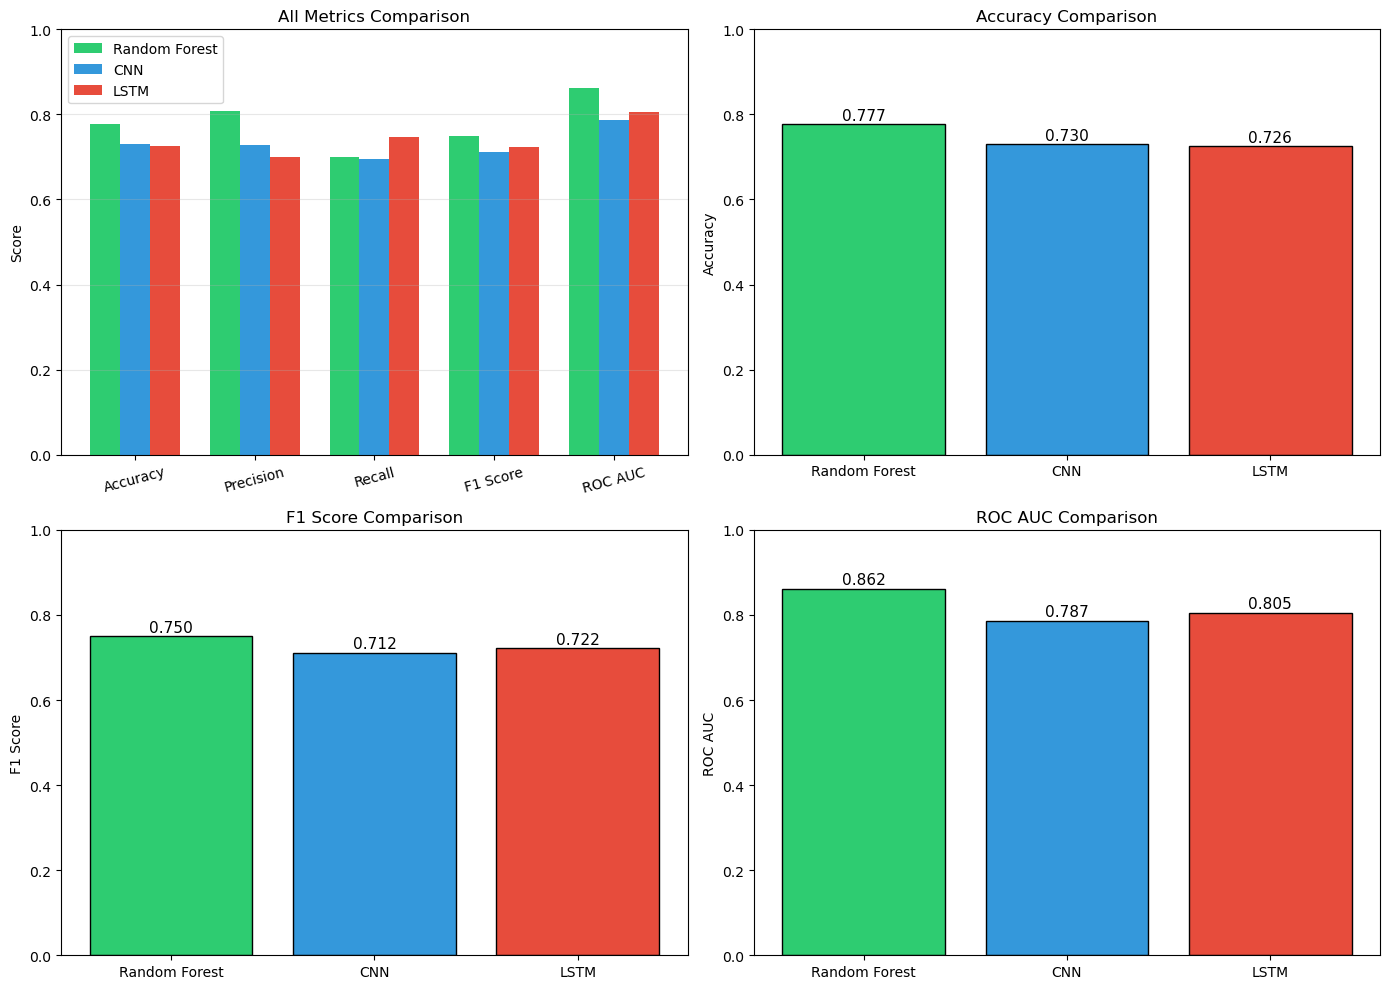


Best Model (by F1 Score): Random Forest
  Accuracy: 0.7773
  F1 Score: 0.7502
  ROC AUC: 0.8619


In [12]:
# final model comparison
print("Model Performance Comparison")

# results table
print("\nResults Table:")
print(results_df.round(4).to_string())

# comparison visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

model_names = ['Random Forest', 'CNN', 'LSTM']
colors = ['#2ecc71', '#3498db', '#e74c3c']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']

# 1. all metrics comparison bar chart
ax = axes[0, 0]
x = np.arange(len(metrics))
width = 0.25
for i, (name, color) in enumerate(zip(model_names, colors)):
    values = [results[name][m] for m in metrics]
    ax.bar(x + i * width, values, width, label=name, color=color)
ax.set_xticks(x + width)
ax.set_xticklabels(metrics, rotation=15)
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('All Metrics Comparison')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 2. accuracy comparison
ax = axes[0, 1]
accuracies = [results[name]['Accuracy'] for name in model_names]
bars = ax.bar(model_names, accuracies, color=colors, edgecolor='black')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1)
ax.set_title('Accuracy Comparison')
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
            f'{acc:.3f}', ha='center', fontsize=11)

# 3. F1 score comparison
ax = axes[1, 0]
f1_scores = [results[name]['F1 Score'] for name in model_names]
bars = ax.bar(model_names, f1_scores, color=colors, edgecolor='black')
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1)
ax.set_title('F1 Score Comparison')
for bar, f1 in zip(bars, f1_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
            f'{f1:.3f}', ha='center', fontsize=11)

# 4. ROC AUC comparison
ax = axes[1, 1]
aucs = [results[name]['ROC AUC'] for name in model_names]
bars = ax.bar(model_names, aucs, color=colors, edgecolor='black')
ax.set_ylabel('ROC AUC')
ax.set_ylim(0, 1)
ax.set_title('ROC AUC Comparison')
for bar, auc in zip(bars, aucs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
            f'{auc:.3f}', ha='center', fontsize=11)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# best model
best_model = max(results.keys(), key=lambda x: results[x]['F1 Score'])
print(f"\nBest Model (by F1 Score): {best_model}")
print(f"  Accuracy: {results[best_model]['Accuracy']:.4f}")
print(f"  F1 Score: {results[best_model]['F1 Score']:.4f}")
print(f"  ROC AUC: {results[best_model]['ROC AUC']:.4f}")

## Save Models and Results

In [ ]:
# save trained models
print("Saving models...")
joblib.dump(trained_models['Random Forest'], OUTPUT_DIR / 'random_forest_model.joblib')
trained_models['CNN'].save(OUTPUT_DIR / 'cnn_model.keras')
trained_models['LSTM'].save(OUTPUT_DIR / 'lstm_model.keras')
joblib.dump(scaler, OUTPUT_DIR / 'scaler.joblib')

# save results
results_output = {
    'dataset': {
        'total_samples': len(y),
        'tornado_samples': int(y.sum()),
        'non_tornado_samples': int((y == 0).sum()),
        'features': X_df.shape[1],
    },
    'results': {name: {k: float(v) for k, v in metrics.items()} for name, metrics in results.items()},
}

with open(OUTPUT_DIR / 'results.json', 'w') as f:
    json.dump(results_output, f, indent=2)

# save predictions
predictions_df = pd.DataFrame({
    'actual': y_test,
    'random_forest_prob': predictions['Random Forest'],
    'cnn_prob': predictions['CNN'],
    'lstm_prob': predictions['LSTM'],
})
predictions_df.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)

print(f"\nAll outputs saved to: {OUTPUT_DIR.resolve()}")
print("  - random_forest_model.joblib")
print("  - cnn_model.keras")
print("  - lstm_model.keras")
print("  - scaler.joblib")
print("  - results.json")
print("  - predictions.csv")
print("  - data_visualization.png")
print("  - model_evaluation.png")
print("  - model_comparison.png")

In [ ]:
# download on colab
if IN_COLAB:
    from google.colab import files
    for f in OUTPUT_DIR.glob('*'):
        files.download(str(f))